# Module 08 — Exercises — Solutions

These exercises follow the order of the concept guide: the discrete families (Binomial, Poisson), the
continuous ones (Exponential, Normal, Beta, Gamma), then the limit theorems and Monte Carlo. Several checks
compare your answer against a *hidden* value, so compute carefully rather than guessing; `scipy.stats` is
allowed wherever the prompt does not forbid it.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, exp, factorial, log, sqrt, pi
from scipy import stats
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Binomial and Poisson probabilities with scipy.stats  `★☆☆`

A product page converts 10% of visitors; 20 visitors arrive. A help desk receives on average 3 calls per
hour. Using `scipy.stats.binom` and `scipy.stats.poisson` (methods `pmf`, `cdf`, `sf`, `ppf`), assign these
**floats** (and one **int**):

* `p_exactly_3` — exactly 3 of the 20 visitors buy;
* `p_at_most_3` — at most 3 buy;
* `p_at_least_5` — at least 5 buy (careful: `sf(k)` is $P(X > k)$, strictly greater);
* `k_95` — the smallest integer $k$ with $P(S \le k) \ge 0.95$ (an `int`);
* `p_pois_0` — no call in a given hour;
* `p_pois_ge_6` — six or more calls in an hour;
* `lam_1pct` — the hourly rate $\lambda$ at which the probability of a call-free hour would be exactly 1% (solve $e^{-\lambda} = 0.01$ by hand).

In [3]:
p_exactly_3 = float(stats.binom.pmf(3, 20, 0.1))
p_at_most_3 = float(stats.binom.cdf(3, 20, 0.1))
p_at_least_5 = float(stats.binom.sf(4, 20, 0.1))
k_95 = int(stats.binom.ppf(0.95, 20, 0.1))
p_pois_0 = float(stats.poisson.pmf(0, 3))
p_pois_ge_6 = float(stats.poisson.sf(5, 3))
lam_1pct = float(-log(0.01))

**Check your answer:**

In [4]:
check_close('P(exactly 3 of 20 buy) = C(20,3) 0.1^3 0.9^17', p_exactly_3, comb(20, 3) * 0.1**3 * 0.9**17)
check_hash('P(at most 3 buy)', p_at_most_3, '8b523e0607ff8f89', decimals=4)
check_hash('P(at least 5 buy)', p_at_least_5, '78a3cda9fa9d7f95', decimals=4)
try:
    k_int = int(k_95) if float(k_95) == int(k_95) else None     # a whole-number float, which is what scipy's ppf returns, is just as right as an int
except Exception:
    k_int = None
check_hash('95% quantile of the purchase count', k_int, '4b227777d4dd1fc6')
check_close('P(no call in an hour) = e^-3', p_pois_0, exp(-3))
check_hash('P(6 or more calls)', p_pois_ge_6, '5ecc6cc295cbfd42', decimals=4)
check_hash('rate for a 1% chance of a call-free hour', lam_1pct, 'd099ef8117a2716b', decimals=3)
try:
    consistent = abs((1 - p_at_most_3) - (stats.binom.pmf(4, 20, 0.1) + p_at_least_5)) < 1e-9
except Exception:
    consistent = False
check('consistency: 1 - P(<= 3) = P(= 4) + P(>= 5)', consistent)

✅ P(exactly 3 of 20 buy) = C(20,3) 0.1^3 0.9^17
✅ P(at most 3 buy)
✅ P(at least 5 buy)
✅ 95% quantile of the purchase count
✅ P(no call in an hour) = e^-3
✅ P(6 or more calls)
✅ rate for a 1% chance of a call-free hour
✅ consistency: 1 - P(<= 3) = P(= 4) + P(>= 5)


True

**Why this works**

`pmf`, `cdf` and `sf` are the three ways of slicing a discrete distribution, and the off-by-one trap is the
survival function: `binom.sf(4, 20, 0.1)` is $P(S > 4) = P(S \ge 5)$, so "at least 5" needs `sf(4)`, not
`sf(5)`. `ppf(0.95)` returns the smallest $k$ whose CDF reaches 0.95 — here 4, because
$P(S \le 3) = 0.867 < 0.95 \le P(S \le 4) = 0.957$. For the Poisson, $P(N = 0) = e^{-\lambda}$, so a 1% chance of
a quiet hour means $\lambda = -\ln 0.01 = 4.605$ calls per hour. The consistency check guards against the
most common slip, mixing up strict and non-strict inequalities.

## Exercise 2 — Implement the Poisson PMF from scratch and watch the Binomial converge  `★☆☆`

Implement, with NumPy only (no `scipy.stats`, no `math.factorial` — which overflows for large $k$):

* `poisson_pmf(k, lam)` → $e^{-\lambda}\lambda^k/k!$ for an integer or integer array `k`; compute it in log
  space as $\exp(-\lambda + k\ln\lambda - \ln k!)$ with $\ln k! = \sum_{j=1}^{k}\ln j$ so that
  `poisson_pmf(200, 150)` works without overflow;
* `poisson_cdf(k, lam)` → $P(N \le k)$ as a float, by summing the PMF;
* `binomial_pmf(k, n, p)` → $\binom{n}{k}p^k(1-p)^{n-k}$ (here `comb` is fine).

Then compute `diff_180`, the largest absolute difference over $k = 0, \dots, 39$ between
`binomial_pmf(k, 180, 1/60)` and `poisson_pmf(k, 3)` — the guide's "180 customers each calling with
probability 1/60" example.

In [5]:
def poisson_pmf(k, lam):
    k = np.asarray(k)
    log_p = -lam + k * np.log(lam) - np.array([sum(np.log(np.arange(1, kk + 1))) for kk in np.atleast_1d(k)]).reshape(k.shape)
    return np.exp(log_p)

def poisson_cdf(k, lam):
    return float(np.sum(poisson_pmf(np.arange(0, int(k) + 1), lam)))

def binomial_pmf(k, n, p):
    return comb(n, k) * p**k * (1 - p) ** (n - k)

diff_180 = max(abs(binomial_pmf(k, 180, 1/60) - float(poisson_pmf(k, 3))) for k in range(0, 40))

**Check your answer:**

In [6]:
try:
    got = np.asarray(poisson_pmf(np.arange(0, 16), 3), dtype=float)
except Exception:
    got = None
check_close('poisson_pmf(k, 3) matches scipy for k = 0..15', got, stats.poisson.pmf(np.arange(0, 16), 3), tol=1e-9)
try:
    got = float(poisson_pmf(200, 150))
except Exception:
    got = None
check_close('poisson_pmf(200, 150) computed in log space (no overflow)', got, float(stats.poisson.pmf(200, 150)), tol=1e-12)
try:
    got = poisson_cdf(3, 3)
except Exception:
    got = None
check_hash('P(N <= 3) for lambda = 3', got, 'f123ba654da7cabb', decimals=4)
try:
    got = binomial_pmf(2, 20, 0.1)
except Exception:
    got = None
check_close('binomial_pmf(2, 20, 0.1)', got, 190 * 0.01 * 0.9**18)
check_hash('largest |Binomial(180, 1/60) - Poisson(3)| over k = 0..39', diff_180, '833fda4ddb19835e', decimals=4)
check('the two PMFs differ by less than 0.002 everywhere', diff_180 is not None and diff_180 < 0.002)

✅ poisson_pmf(k, 3) matches scipy for k = 0..15
✅ poisson_pmf(200, 150) computed in log space (no overflow)
✅ P(N <= 3) for lambda = 3
✅ binomial_pmf(2, 20, 0.1)
✅ largest |Binomial(180, 1/60) - Poisson(3)| over k = 0..39
✅ the two PMFs differ by less than 0.002 everywhere


True

**Why this works**

Working in log space is the professional habit: $150^{200}$ and $200!$ both overflow a double, but
$-150 + 200\ln 150 - \ln 200! \approx -11.1$ is a perfectly ordinary number whose exponential is
$1.5 \times 10^{-5}$. (`scipy.special.gammaln(k + 1)` is the library version of $\ln k!$.) The Binomial–Poisson
comparison shows the limit in Section 4 of the guide at work: with $n = 180$ and $p = 1/60$ the largest gap
over all $k$ is below $0.002$, so for "many rare trials" the one-parameter Poisson replaces the two-parameter
Binomial at essentially no cost. A common slip is to apply `np.log` to the integer array `k` directly for
$\ln k!$ — you need the cumulative sum of $\ln j$, not $\ln k$.

## Exercise 3 — Choose the distribution  `★☆☆`

For each quantity, name the most appropriate named distribution, its parameters (in words), and one
assumption that must hold for it to be right:

1. The number of defective screws in a box of 200 from a line with a 1.5% defect rate.
2. The number of e-mails arriving in a 10-minute window at a server that receives 300 per hour.
3. The time until the next e-mail arrives at that server.
4. The number of cold calls a salesperson makes until the first sale, if each call succeeds with probability 0.04.
5. The time until the third e-mail arrives.
6. Your uncertainty about a coin's probability of heads after seeing 12 heads in 20 flips, starting from no prior preference.
7. The class label (one of 10 digits) that an image classifier predicts, as a random variable.
8. The average of 50 independent measurements of a resistor, each with a slightly skewed error distribution.
9. The number of insurance claims per policyholder per year, when the sample variance of the counts is five times the sample mean.

**Answer**

1. Binomial($n = 200$, $p = 0.015$) — screws must be defective independently with the same probability; since
   $n$ is large and $p$ small, Poisson($3$) is an excellent approximation.
2. Poisson($\lambda = 300 \times 10/60 = 50$) — arrivals must be independent at a constant rate (no bursts, no
   batch deliveries); if the variance of the counts exceeds the mean, use a Negative Binomial.
3. Exponential(rate $= 300$ per hour $= 5$ per minute) — same Poisson-process assumption; mean 12 seconds.
4. Geometric($p = 0.04$) on the trial number — calls independent with constant success probability; mean 25 calls.
5. Gamma(shape 3, rate 5 per minute) — the sum of three independent Exponential inter-arrival times; mean 36 seconds.
6. Beta($1 + 12, 1 + 8$) $=$ Beta(13, 9) — a Uniform (Beta(1, 1)) prior updated with 12 successes and 8
   failures; it requires the flips to be independent given the coin's bias.
7. Categorical over 10 classes with probability vector given by the softmax output; the one-hot label is
   its sample, and the multinomial would describe the class counts over many images.
8. Approximately Normal($\mu$, $\sigma^2/50$) by the central limit theorem — the measurements must be
   independent with finite variance; skewness $\gamma_1$ of a single measurement leaves a residual skewness of
   $\gamma_1/\sqrt{50}$ in the average, which is small for mild skew.
9. Negative Binomial (mean $\mu$, dispersion $r$ with $\mu + \mu^2/r = 5\mu$) — a Poisson would force variance
   $=$ mean and understate every tail probability; the heterogeneity across policyholders (a Gamma-distributed
   rate) is exactly what the Negative Binomial models.

## Exercise 4 — Exponential quantiles, tails and memorylessness  `★★☆`

Buses arrive as a Poisson process with rate $\lambda = 0.2$ per minute. Implement, with NumPy only:

* `expon_quantile(q, lam)` → the $q$-quantile of $\text{Exponential}(\lambda)$, by inverting $F(t) = 1 - e^{-\lambda t}$;
* `expon_tail(t, lam)` → $P(T > t)$;
* `conditional_tail(s, t, lam)` → $P(T > s + t \mid T > s)$ computed *from the definition* of conditional
  probability (ratio of two tail probabilities), not by assuming memorylessness;
* `sample_expon(n, lam, rng)` → `n` samples via the inverse-CDF method `-np.log(rng.random(n)) / lam`.

Then verify numerically that `conditional_tail(5, 10, 0.2)` equals `expon_tail(10, 0.2)`, and that the
empirical version — among 50,000 simulated waits longer than 5 minutes, the fraction longer than 15 — agrees.

In [7]:
def expon_quantile(q, lam):
    return float(-np.log(1 - q) / lam)

def expon_tail(t, lam):
    return float(np.exp(-lam * t))

def conditional_tail(s, t, lam):
    return float(np.exp(-lam * (s + t)) / np.exp(-lam * s))

def sample_expon(n, lam, rng):
    return -np.log(rng.random(n)) / lam

**Check your answer:**

In [8]:
try:
    got = expon_quantile(0.5, 0.2)
except Exception:
    got = None
check_hash('median waiting time (minutes)', got, '454bc3af835a6e4f', decimals=3)
try:
    got = expon_quantile(0.9, 0.2)
except Exception:
    got = None
check_hash('90th percentile of the wait', got, '488a6176fdb708a5', decimals=3)
try:
    got = expon_quantile(0.9, 0.2)
    ok_scipy = abs(got - stats.expon(scale=1/0.2).ppf(0.9)) < 1e-9
except Exception:
    ok_scipy = False
check('quantile agrees with scipy expon(scale=1/lam).ppf', ok_scipy)
try:
    got = expon_tail(10, 0.2)
except Exception:
    got = None
check_close('P(T > 10) = e^-2', got, exp(-2))
try:
    got = conditional_tail(5, 10, 0.2)
except Exception:
    got = None
check_hash('P(T > 15 | T > 5)', got, '81a66bf490ca518a', decimals=4)
try:
    memoryless = abs(conditional_tail(5, 10, 0.2) - expon_tail(10, 0.2)) < 1e-12
except Exception:
    memoryless = False
check('memorylessness: P(T > 15 | T > 5) == P(T > 10)', memoryless)
try:
    s = np.asarray(sample_expon(50_000, 0.2, np.random.default_rng(3)), dtype=float)
    ok_shape = s.shape == (50_000,) and np.all(s > 0)
    emp = float(np.mean(s[s > 5] > 15))
    ok_mean = abs(s.mean() - 5) < 0.1
except Exception:
    ok_shape, emp, ok_mean = False, None, False
check('sampler returns 50,000 positive values with mean close to 5', ok_shape and ok_mean)
check('empirical conditional tail within 0.02 of e^-2', emp is not None and abs(emp - exp(-2)) < 0.02)

✅ median waiting time (minutes)
✅ 90th percentile of the wait
✅ quantile agrees with scipy expon(scale=1/lam).ppf
✅ P(T > 10) = e^-2
✅ P(T > 15 | T > 5)
✅ memorylessness: P(T > 15 | T > 5) == P(T > 10)
✅ sampler returns 50,000 positive values with mean close to 5
✅ empirical conditional tail within 0.02 of e^-2


True

**Why this works**

Inverting the CDF gives $Q(q) = -\ln(1-q)/\lambda$: the median is $\ln 2/0.2 = 3.47$ minutes and the 90th
percentile $-\ln(0.1)/0.2 = 11.5$ minutes — the mean of 5 minutes is neither. The conditional tail is
$e^{-\lambda(s+t)}/e^{-\lambda s} = e^{-\lambda t}$, which is exactly $P(T > t)$: that cancellation *is*
memorylessness, and the simulation confirms it by filtering (keep the waits above 5 and ask about 15). The
sampler is inverse-CDF sampling with $U$ in place of $1 - U$ (same distribution). The classic error is to
write the tail as $e^{-t/\lambda}$ — mixing up rate and scale — which the comparison with
`expon(scale=1/lam)` catches.

## Exercise 5 — Normal z-scores and a quality-control problem  `★★☆`

A filling machine dispenses $\mathcal{N}(500, 4^2)$ grams. Implement (you may use `scipy.stats.norm`, but
all arguments must be converted to $z$-scores first — the check inspects `z_score`):

* `z_score(x, mu, sigma)` → $(x - \mu)/\sigma$;
* `p_below(x, mu, sigma)` → $P(X < x)$;
* `p_between(a, b, mu, sigma)` → $P(a < X < b)$;
* `sigma_for_tail(limit, mu, target_prob)` → the largest $\sigma$ such that $P(X < \text{limit}) \le$ `target_prob`
  (for `limit < mu`): solve $\Phi\big((\text{limit} - \mu)/\sigma\big) = $ `target_prob` for $\sigma$;
* `two_sided_interval(mu, sigma, coverage)` → the tuple $(\mu - z\sigma, \mu + z\sigma)$ containing the central
  `coverage` fraction of the mass (e.g. $z = 1.96$ for 0.95).

Questions answered by the checks: the fraction of packets below 490 g; the fraction within $\pm 5$ g; the
$\sigma$ needed so that at most 0.1% of packets fall below 490 g; the central 99% interval; and the
fraction of adults taller than 180 cm if heights are $\mathcal{N}(165, 7^2)$.

In [9]:
def z_score(x, mu, sigma):
    return (x - mu) / sigma

def p_below(x, mu, sigma):
    return float(stats.norm.cdf(z_score(x, mu, sigma)))

def p_between(a, b, mu, sigma):
    return float(stats.norm.cdf(z_score(b, mu, sigma)) - stats.norm.cdf(z_score(a, mu, sigma)))

def sigma_for_tail(limit, mu, target_prob):
    # largest sigma such that P(X < limit) <= target_prob, for limit < mu
    return float((mu - limit) / stats.norm.ppf(1 - target_prob))

def two_sided_interval(mu, sigma, coverage):
    z = stats.norm.ppf(0.5 + coverage / 2)
    return (float(mu - z * sigma), float(mu + z * sigma))

**Check your answer:**

In [10]:
try:
    got = z_score(490, 500, 4)
except Exception:
    got = None
check_close('z-score of 490 g is -2.5', got, -2.5)
try:
    got = p_below(490, 500, 4)
except Exception:
    got = None
check_hash('fraction of packets below 490 g', got, '180d7f3662b77c66', decimals=4)
try:
    got = p_between(495, 505, 500, 4)
except Exception:
    got = None
check_hash('fraction within +/- 5 g', got, '28684632ee2e568b', decimals=4)
try:
    got = p_between(496, 504, 500, 4)
except Exception:
    got = None
check_close('68.27% within one sigma', got, stats.norm.cdf(1) - stats.norm.cdf(-1))
try:
    got = sigma_for_tail(490, 500, 0.001)
    ok_round_trip = abs(p_below(490, 500, got) - 0.001) < 1e-9
except Exception:
    got, ok_round_trip = None, False
check_hash('sigma needed for at most 0.1% below 490 g', got, 'ecb4142095b56ccc', decimals=3)
check('round trip: p_below(490, 500, sigma_for_tail(...)) == 0.001', ok_round_trip)
try:
    lo, hi = two_sided_interval(500, 4, 0.99)
except Exception:
    lo, hi = None, None
check_hash('central 99% interval', (lo, hi), '2db6b970f890bffc', decimals=3)
try:
    got = 1 - p_below(180, 165, 7)
except Exception:
    got = None
check_hash('fraction of adults taller than 180 cm', got, 'c863449e5baa2995', decimals=4)

✅ z-score of 490 g is -2.5
✅ fraction of packets below 490 g
✅ fraction within +/- 5 g
✅ 68.27% within one sigma
✅ sigma needed for at most 0.1% below 490 g
✅ round trip: p_below(490, 500, sigma_for_tail(...)) == 0.001
✅ central 99% interval
✅ fraction of adults taller than 180 cm


True

**Why this works**

Everything reduces to the standard Normal through $z = (x - \mu)/\sigma$. $490$ g is $z = -2.5$, so
$\Phi(-2.5) = 0.0062$ of packets are underweight; $\pm 5$ g is $\pm 1.25\sigma$, covering $0.789$. For the
engineering target invert the problem: $\Phi(-10/\sigma) = 0.001$ means $10/\sigma = \Phi^{-1}(0.999) = 3.09$,
so $\sigma = 3.24$ g — a 19% reduction in variability. The central 99% interval uses $z = \Phi^{-1}(0.995) = 2.576$,
not $2.326$ (that is the one-sided 99% point) — the most frequent mistake in this exercise. The height
question is the same arithmetic with $z = 15/7 = 2.14$, giving $1.6\%$.

## Exercise 6 — A Beta posterior for a conversion rate  `★★☆`

A landing page is believed, before any data, to convert with a rate described by a $\text{Beta}(2, 2)$ prior.
It then converts 7 of 50 visitors. Implement

* `beta_posterior(a0, b0, successes, failures)` → the tuple `(a, b)` of the posterior Beta parameters;
* `beta_mean(a, b)` and `beta_sd(a, b)` → the mean $\frac{a}{a+b}$ and standard deviation $\sqrt{\frac{ab}{(a+b)^2(a+b+1)}}$ as floats;
* `credible_interval(a, b, level=0.95)` → the tuple of the $\frac{1-\text{level}}{2}$ and $1 - \frac{1-\text{level}}{2}$ quantiles (`scipy.stats.beta.ppf`);
* `prob_b_beats_a(a_A, b_A, a_B, b_B, n_samples, rng)` → the Monte Carlo probability that a draw from
  $\text{Beta}(a_B, b_B)$ exceeds a draw from $\text{Beta}(a_A, b_A)$, using `rng.beta(a_B, b_B, n_samples)` **first** and
  `rng.beta(a_A, b_A, n_samples)` second.

Then compare the posterior mean with the raw rate $7/50$ and the prior mean $0.5$, and compute the posterior
mean you would get from 70 conversions in 500 visits (same rate, ten times the data).

In [11]:
def beta_posterior(a0, b0, successes, failures):
    return (a0 + successes, b0 + failures)

def beta_mean(a, b):
    return a / (a + b)

def beta_sd(a, b):
    return float(np.sqrt(a * b / ((a + b) ** 2 * (a + b + 1))))

def credible_interval(a, b, level=0.95):
    lo = float(stats.beta.ppf((1 - level) / 2, a, b))
    hi = float(stats.beta.ppf(1 - (1 - level) / 2, a, b))
    return (lo, hi)

def prob_b_beats_a(a_A, b_A, a_B, b_B, n_samples, rng):
    return float(np.mean(rng.beta(a_B, b_B, n_samples) > rng.beta(a_A, b_A, n_samples)))

**Check your answer:**

In [12]:
try:
    a, b = beta_posterior(2, 2, 7, 43)
except Exception:
    a, b = None, None
check('posterior parameters are (9, 45)', (a, b) == (9, 45))
try:
    got = beta_mean(9, 45)
except Exception:
    got = None
check_hash('posterior mean', got, 'c93110febcea19c2', decimals=4)
try:
    got = beta_sd(9, 45)
except Exception:
    got = None
check_hash('posterior standard deviation', got, 'fa1ddc57f4c4392d', decimals=4)
try:
    got = beta_sd(1, 1)
except Exception:
    got = None
check_close('sd of Beta(1, 1) = Uniform is 1/sqrt(12)', got, 1/sqrt(12))
try:
    got = credible_interval(9, 45, 0.95)
except Exception:
    got = None
check_hash('95% credible interval', got, 'fc8790774cfdd03f', decimals=3)
try:
    got = prob_b_beats_a(9, 45, 14, 40, 200_000, np.random.default_rng(11))
except Exception:
    got = None
check('P(theta_B > theta_A) is close to 0.885 (within 0.01)', got is not None and abs(got - 0.885) < 0.01)
try:
    got = beta_mean(*beta_posterior(2, 2, 70, 430))
except Exception:
    got = None
check_hash('posterior mean with ten times the data', got, '3df39ca6313dbf0f', decimals=4)
check('more data pulls the mean to within 0.01 of the raw rate 0.14', got is not None and abs(got - 0.14) < 0.01)

✅ posterior parameters are (9, 45)
✅ posterior mean
✅ posterior standard deviation
✅ sd of Beta(1, 1) = Uniform is 1/sqrt(12)
✅ 95% credible interval
✅ P(theta_B > theta_A) is close to 0.885 (within 0.01)
✅ posterior mean with ten times the data
✅ more data pulls the mean to within 0.01 of the raw rate 0.14


True

**Why this works**

Beta–Binomial conjugacy makes the update pure bookkeeping: successes are added to $a$, failures to $b$, so
$\text{Beta}(2, 2)$ becomes $\text{Beta}(9, 45)$ with mean $9/54 = 0.167$ — between the raw rate $0.14$ and the
prior mean $0.5$, because the prior counts as 4 pseudo-observations against 50 real ones. With 500 visits the
prior is 4 against 500 and the posterior mean $72/504 = 0.143$ is almost the raw rate; the standard deviation
shrinks by about $\sqrt{10}$. The credible interval is read straight off the posterior quantiles, and
$P(\theta_B > \theta_A)$ is a one-line Monte Carlo estimate — compare the contortions a frequentist test
needs for the same question. The typical slip is to add the number of *trials* to $b$ instead of the number of
failures.

## Exercise 7 — Gamma waiting times and the Gamma–Poisson identity  `★★☆`

Buses arrive at rate $\lambda = 0.2$ per minute; the time until the $k$-th bus is $\text{Gamma}(k, \lambda)$ with
integer shape $k$ (an *Erlang* distribution). Implement, using NumPy and `math.factorial` only (no `scipy.stats`
inside the functions):

* `gamma_pdf(x, k, lam)` → the density $\frac{\lambda^k}{(k-1)!}x^{k-1}e^{-\lambda x}$ for $x > 0$ (0 otherwise), vectorised over `x`;
* `gamma_tail_via_poisson(t, k, lam)` → $P(\text{$k$-th bus arrives after } t)$ computed as the Poisson
  probability of **at most $k - 1$ arrivals** in $[0, t]$, $\sum_{j=0}^{k-1} e^{-\lambda t}(\lambda t)^j/j!$;
* `sample_gamma_as_sum(n, k, lam, rng)` → `n` samples as sums of `k` independent Exponentials, drawn with a single
  call `rng.exponential(1/lam, size=(n, k))` summed along axis 1.

Then confirm that `gamma_tail_via_poisson(20, 3, 0.2)` equals `scipy.stats.gamma.sf(20, a=3, scale=5)` and that the
empirical tail of 100,000 simulated third-bus times agrees.

In [13]:
def gamma_pdf(x, k, lam):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    pos = x > 0
    out[pos] = lam**k * x[pos] ** (k - 1) * np.exp(-lam * x[pos]) / factorial(k - 1)
    return out

def gamma_tail_via_poisson(t, k, lam):
    # P(k-th event after time t) = P(at most k-1 events in [0, t]) with count ~ Poisson(lam t)
    mu = lam * t
    return float(sum(np.exp(-mu) * mu**j / factorial(j) for j in range(k)))

def sample_gamma_as_sum(n, k, lam, rng):
    return rng.exponential(1 / lam, size=(n, k)).sum(axis=1)

**Check your answer:**

In [14]:
try:
    got = float(np.asarray(gamma_pdf(10.0, 3, 0.2)).ravel()[0])
except Exception:
    got = None
check_hash('Gamma(3, 0.2) density at x = 10', got, 'b7a80220a59886f3', decimals=4)
try:
    xs = np.linspace(0.5, 40, 80)
    got = np.asarray(gamma_pdf(xs, 3, 0.2), dtype=float)
except Exception:
    got = None
check_close('gamma_pdf matches scipy gamma.pdf on a grid', got, stats.gamma.pdf(np.linspace(0.5, 40, 80), a=3, scale=5), tol=1e-9)
try:
    got = np.asarray(gamma_pdf(np.array([-1.0, 0.0]), 3, 0.2), dtype=float)
except Exception:
    got = None
check_close('density is 0 for x <= 0', got, np.array([0.0, 0.0]))
try:
    got = gamma_tail_via_poisson(20, 3, 0.2)
except Exception:
    got = None
check_hash('P(third bus after 20 minutes)', got, '3e575a0e767f3f03', decimals=4)
check_close('Gamma tail equals Poisson CDF: matches scipy gamma.sf(20, a=3, scale=5)', got, float(stats.gamma.sf(20, a=3, scale=5)), tol=1e-9)
try:
    got = gamma_tail_via_poisson(5, 1, 0.2)
except Exception:
    got = None
check_close('k = 1 reduces to the Exponential tail e^-1', got, exp(-1))
try:
    g = np.asarray(sample_gamma_as_sum(100_000, 3, 0.2, np.random.default_rng(5)), dtype=float)
    ok = g.shape == (100_000,) and abs(g.mean() - 15) < 0.15 and abs(np.mean(g > 20) - stats.gamma.sf(20, a=3, scale=5)) < 0.01
except Exception:
    ok = False
check('simulated third-bus times: mean about 15 and tail about 0.238', ok)

✅ Gamma(3, 0.2) density at x = 10
✅ gamma_pdf matches scipy gamma.pdf on a grid
✅ density is 0 for x <= 0
✅ P(third bus after 20 minutes)
✅ Gamma tail equals Poisson CDF: matches scipy gamma.sf(20, a=3, scale=5)
✅ k = 1 reduces to the Exponential tail e^-1
✅ simulated third-bus times: mean about 15 and tail about 0.238


True

**Why this works**

"The third bus arrives after time $t$" and "at most two buses arrived by time $t$" are the same event, so the
Gamma tail is a Poisson CDF: $P(G > 20) = e^{-4}(1 + 4 + 8) = 0.238$. This identity is how the Gamma, the
Exponential ($k = 1$) and the Poisson process fit together, and it is also how `scipy` could evaluate the
Erlang tail without any special function. The density needs $(k-1)!$, not $k!$ — the Gamma function
satisfies $\Gamma(k) = (k-1)!$ — and must be zero for $x \le 0$; the simulation (sums of Exponentials) is the
generative story made literal, and its mean $k/\lambda = 15$ confirms the parametrisation.

## Exercise 8 — Verify the central limit theorem (and watch it fail)  `★★☆`

Implement

* `standardised_means(sampler, n, reps, mu, sigma, rng)` → a NumPy array of `reps` values
  $\sqrt{n}\,(\bar X_n - \mu)/\sigma$, where `sampler(rng, size)` returns an array of the given shape (call it
  **once** with `size=(reps, n)` and average along axis 1);
* `kolmogorov_distance(z)` → $\sup_z |F_{\text{emp}}(z) - \Phi(z)|$ between the empirical CDF of the sample and the
  standard Normal CDF (sort the sample; the sup is attained just before or at a data point — compare both
  $\frac{i}{m} - \Phi(z_{(i)})$ and $\Phi(z_{(i)}) - \frac{i-1}{m}$);
* `skewness(z)` → the sample skewness $\frac{\frac1m\sum(z_i - \bar z)^3}{\big(\frac1m\sum(z_i - \bar z)^2\big)^{3/2}}$.

Then test the CLT: for an Exponential(1) source ($\mu = \sigma = 1$) with $n = 30$ and 20,000 repetitions the
standardised means should have mean $\approx 0$, variance $\approx 1$, Kolmogorov distance below 0.04 and skewness
near $2/\sqrt{30} = 0.365$. For a Cauchy source (use $\mu = 0$, $\sigma = 1$ as *nominal* values) the variance
of the "standardised means" should blow up and the Kolmogorov distance should stay large for every $n$.

In [15]:
def standardised_means(sampler, n, reps, mu, sigma, rng):
    x = np.asarray(sampler(rng, (reps, n)), dtype=float).mean(axis=1)
    return np.sqrt(n) * (x - mu) / sigma

def kolmogorov_distance(z):
    z = np.sort(np.asarray(z, dtype=float))
    m = len(z)
    F = stats.norm.cdf(z)
    return float(max(np.max(np.arange(1, m + 1) / m - F), np.max(F - np.arange(0, m) / m)))

def skewness(z):
    z = np.asarray(z, dtype=float)
    c = z - z.mean()
    return float(np.mean(c**3) / np.mean(c**2) ** 1.5)

**Check your answer:**

In [16]:
expo = lambda rng, size: rng.exponential(1.0, size)
try:
    z = np.asarray(standardised_means(expo, 30, 20_000, 1.0, 1.0, np.random.default_rng(1)), dtype=float)
    ok_shape = z.shape == (20_000,)
except Exception:
    z, ok_shape = None, False
check('returns 20,000 standardised means', ok_shape)
check('mean of standardised means is within 0.03 of 0', ok_shape and abs(z.mean()) < 0.03)
check('variance of standardised means is within 0.05 of 1', ok_shape and abs(z.var() - 1) < 0.05)
try:
    kd = kolmogorov_distance(z)
except Exception:
    kd = None
check('Kolmogorov distance to N(0,1) below 0.04 for exponential means of 30', kd is not None and kd < 0.04)
try:
    kd_normal = kolmogorov_distance(stats.norm.ppf((np.arange(1, 1001) - 0.5) / 1000))
except Exception:
    kd_normal = None
check_close('Kolmogorov distance of perfect Normal quantiles is 0.0005', kd_normal, 0.0005, tol=1e-9)
try:
    kd1 = kolmogorov_distance(standardised_means(expo, 1, 20_000, 1.0, 1.0, np.random.default_rng(2)))
except Exception:
    kd1 = None
check('n = 1 (no averaging): distance is large, about 0.16 (within 0.02)', kd1 is not None and abs(kd1 - 0.1587) < 0.02)
try:
    sk = skewness(z)
except Exception:
    sk = None
check('skewness of the means is near 2/sqrt(30) = 0.365 (within 0.08)', sk is not None and abs(sk - 2/sqrt(30)) < 0.08)
try:
    got = skewness(np.array([1.0, 2.0, 3.0, 4.0, 10.0]))
except Exception:
    got = None
check_hash('skewness of [1, 2, 3, 4, 10]', got, '9fc3c77c94302ac0', decimals=4)
try:
    cauchy = lambda rng, size: rng.standard_cauchy(size)
    zc = standardised_means(cauchy, 1000, 20_000, 0.0, 1.0, np.random.default_rng(3))
    ok_cauchy = np.var(zc) > 100 and kolmogorov_distance(zc) > 0.2
except Exception:
    ok_cauchy = False
check('Cauchy source: variance explodes and the distance to the Normal stays large', ok_cauchy)

✅ returns 20,000 standardised means
✅ mean of standardised means is within 0.03 of 0
✅ variance of standardised means is within 0.05 of 1
✅ Kolmogorov distance to N(0,1) below 0.04 for exponential means of 30
✅ Kolmogorov distance of perfect Normal quantiles is 0.0005
✅ n = 1 (no averaging): distance is large, about 0.16 (within 0.02)
✅ skewness of the means is near 2/sqrt(30) = 0.365 (within 0.08)
✅ skewness of [1, 2, 3, 4, 10]


✅ Cauchy source: variance explodes and the distance to the Normal stays large


True

**Why this works**

Standardising by the *true* $\mu$ and $\sigma$ and multiplying by $\sqrt{n}$ removes the $1/\sqrt{n}$ shrinkage,
so what remains is pure shape: for the Exponential at $n = 30$ the result has mean 0, variance 1 and a residual
skewness of $\gamma_1/\sqrt{n} = 0.365$, which is the whole content of the Berry–Esseen story. The Kolmogorov
distance is the natural ruler — $0.16$ at $n = 1$ (an Exponential is not a Normal), about $0.025$ at $n = 30$,
heading to 0 like $1/\sqrt{n}$. For the Cauchy there is no $\mu$ and no $\sigma$; plugging in nominal values
produces "standardised means" whose variance is enormous and grows with `reps`, and whose distance to the
Normal never shrinks — the CLT's finite-variance condition is not a technicality. A common slip in the
Kolmogorov distance is to compare only $i/m$ with $\Phi(z_{(i)})$, missing the jump just below each data point.

## Exercise 9 — Diagnose the argument: 'the law of large numbers guarantees it'  `★★☆`

Three colleagues each invoke the law of large numbers. For each, say whether the conclusion follows, and if
not, name the error precisely and give the correct statement.

1. "Our roulette table has paid out more than expected this week. By the law of large numbers, next week it
   will pay out *less* than expected so that the long-run average is restored."
2. "Our fraud model's per-transaction loss has a heavy tail — a few transactions cost millions. But we
   average the loss over 10 million transactions a day, so by the law of large numbers the daily average is
   essentially constant and we can budget on it."
3. "We evaluate on 200 test examples. By the central limit theorem the accuracy estimate is Normal, so its
   95% interval is $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/200}$ — fine for our model with $\hat p = 0.995$."

**Answer**

1. Gambler's fallacy. The LLN says the *proportion* $\bar X_n$ converges; it says nothing about the *sum*
   $S_n - n\mu$, which does not revert and in fact wanders further (its standard deviation grows like
   $\sqrt{n}$). Next week's spins are independent of this week's and have the same expectation; the excess is
   diluted by future spins, not repaid. Correct statement: the fraction of the long-run total that this week
   represents shrinks toward zero.
2. Two problems. First, the LLN needs a finite *mean*, and the rate of convergence needs a finite *variance*:
   if the loss tail is a power law with index $\alpha \le 2$, the daily average has infinite variance, is
   dominated by the single largest loss, and does not stabilise like $\sigma/\sqrt{n}$ (if $\alpha \le 1$ it does
   not converge at all). Second, the 10 million transactions are not independent (fraud rings, system outages
   produce clusters), so the effective $n$ is far smaller. Correct approach: model the tail explicitly
   (generalised Pareto), budget on a high quantile of the daily total, and reinsure or cap exposures.
3. The CLT is asymptotic and its speed depends on skewness: with $p = 0.995$ and $n = 200$ the expected number of
   errors is just 1, the Bernoulli skewness is $(1 - 2p)/\sqrt{p(1-p)} \approx -14$, and the sampling distribution
   of $\hat p$ is a few discrete spikes, not a bell. The Wald interval $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$
   is badly miscalibrated here (if 0 errors are observed it collapses to a point). Correct approach: use an exact
   Binomial (Clopper–Pearson) or Wilson interval, which for 1 error in 200 gives roughly $[0.97, 1.0]$ — far
   wider than the Wald interval suggests — and recognise that distinguishing 99.5% from 99% needs thousands of
   examples, not 200.

## Exercise 10 — Monte Carlo integration with an error bar, plus antithetic variates  `★★★`

Implement

* `mc_integral(f, a, b, n, rng)` → the tuple `(estimate, standard_error)` for $\int_a^b f(x)\,dx$, using
  `n` uniform points `x = a + (b - a) * rng.random(n)`: the estimate is the mean of $(b-a)f(x_i)$ and the standard
  error is their sample standard deviation (`ddof=1`) divided by $\sqrt{n}$;
* `mc_integral_antithetic(f, a, b, n, rng)` → the same with **antithetic variates**: draw `u = rng.random(n // 2)`,
  evaluate $f$ at both $a + (b-a)u$ and $a + (b-a)(1-u)$, average each pair into one value
  $\frac{b-a}{2}[f(x_1) + f(x_2)]$, and return the mean and standard error (`ddof=1`, divided by $\sqrt{n/2}$)
  of those $n/2$ pair values;
* `samples_needed(sigma, target_se)` → the smallest integer $n$ with $\sigma/\sqrt{n} \le$ `target_se`.

Targets: $\int_0^1 e^{-x^2}\,dx = 0.746824$ and $\int_1^5 \frac{\sin x}{x}\,dx = 0.603848$. Your estimates must be
within 4 standard errors of the truth, and the antithetic standard error for $e^{-x^2}$ must be at least 3 times
smaller than the plain one (the guide predicts about 5 times).

In [17]:
def mc_integral(f, a, b, n, rng):
    u = rng.random(n)
    x = a + (b - a) * u
    vals = (b - a) * f(x)
    return float(vals.mean()), float(vals.std(ddof=1) / np.sqrt(n))

def mc_integral_antithetic(f, a, b, n, rng):
    u = rng.random(n // 2)
    x1 = a + (b - a) * u
    x2 = a + (b - a) * (1 - u)
    vals = 0.5 * (b - a) * (f(x1) + f(x2))
    return float(vals.mean()), float(vals.std(ddof=1) / np.sqrt(len(vals)))

def samples_needed(sigma, target_se):
    return int(np.ceil((sigma / target_se) ** 2))

**Check your answer:**

In [18]:
I1, I2 = 0.7468241328124271, 0.6038481290459576
f1 = lambda x: np.exp(-x**2)
f2 = lambda x: np.sin(x) / x
try:
    est, se = mc_integral(f1, 0.0, 1.0, 10_000, np.random.default_rng(7))
except Exception:
    est, se = None, None
check('plain estimate of int_0^1 exp(-x^2) within 4 SE of 0.746824', est is not None and se is not None and abs(est - I1) < 4 * se)
check('its standard error is about 0.002 (within 0.0005)', se is not None and abs(se - 0.00201) < 0.0005)
check_hash('seeded plain estimate (rng seed 7, n = 10,000)', est, '8e6adeb6703ed174', decimals=4)
try:
    est2, se2 = mc_integral(f2, 1.0, 5.0, 20_000, np.random.default_rng(8))
except Exception:
    est2, se2 = None, None
check('estimate of int_1^5 sin(x)/x within 4 SE of 0.603848', est2 is not None and se2 is not None and abs(est2 - I2) < 4 * se2)
check('the (b - a) factor is applied (estimate is not 0.15)', est2 is not None and est2 > 0.5)
try:
    est_a, se_a = mc_integral_antithetic(f1, 0.0, 1.0, 10_000, np.random.default_rng(7))
except Exception:
    est_a, se_a = None, None
check('antithetic estimate within 4 SE of the truth', est_a is not None and se_a is not None and abs(est_a - I1) < 4 * se_a)
check('antithetic SE at least 3x smaller than plain SE', se is not None and se_a is not None and se_a > 0 and se / se_a > 3)
check_hash('seeded antithetic estimate', est_a, '2755ec8f98da7bf1', decimals=4)
try:
    # equally correct formulas can differ by 1 in floating point here: compare to the nearest thousand
    got = round(int(samples_needed(0.201, 0.0002)), -3)
except Exception:
    got = None
check_hash('samples needed for SE 0.0002 with sigma 0.201 (to the nearest thousand)', got, '8f3fedcf25b94f5a')
try:
    got = samples_needed(1.0, 0.1)
except Exception:
    got = None
check_close('samples_needed(1, 0.1) = 100', got, 100)
try:
    got = samples_needed(1.0, 0.3)
except Exception:
    got = None
check_close('samples_needed(1, 0.3) = 12 (11.1 rounds up, not down)', got, 12)

✅ plain estimate of int_0^1 exp(-x^2) within 4 SE of 0.746824
✅ its standard error is about 0.002 (within 0.0005)
✅ seeded plain estimate (rng seed 7, n = 10,000)
✅ estimate of int_1^5 sin(x)/x within 4 SE of 0.603848
✅ the (b - a) factor is applied (estimate is not 0.15)
✅ antithetic estimate within 4 SE of the truth
✅ antithetic SE at least 3x smaller than plain SE
✅ seeded antithetic estimate
✅ samples needed for SE 0.0002 with sigma 0.201 (to the nearest thousand)
✅ samples_needed(1, 0.1) = 100
✅ samples_needed(1, 0.3) = 12 (11.1 rounds up, not down)


True

**Why this works**

Writing $\int_a^b f = (b-a)\,\mathbb{E}[f(U)]$ with $U \sim \text{Uniform}(a, b)$ turns integration into averaging,
and the CLT supplies the error bar $\hat\sigma/\sqrt{n}$ — forgetting the factor $(b - a)$ is the classic
mistake (the second integral would come out near 0.15 instead of 0.60). For $e^{-x^2}$, $\sigma_g = 0.201$, so
$n = 10{,}000$ gives a standard error of $0.002$ and a target of $0.0002$ needs $(0.201/0.0002)^2 \approx 1{,}010{,}000$
samples. Antithetic variates exploit the monotonicity of $e^{-x^2}$ on $[0, 1]$: $g(U)$ and $g(1-U)$ are
negatively correlated (covariance $-0.0388$ against a variance of $0.0404$), so each pair average has variance
$\frac12(0.0404 - 0.0388) = 0.0008$, roughly 25 times smaller than two independent draws — the same accuracy
for 1/25 of the samples. The standard error of the antithetic estimator must be computed from the *pair
averages*, not from the $n$ individual evaluations, which are no longer independent.

## Exercise 11 — Mini-project: staffing a call centre with Poisson arrivals and Exponential service  `★★★`

A call centre receives calls as a Poisson process at **2 calls per minute** during an 8-hour day; each call
occupies one agent for an **Exponential** time with mean **4 minutes**. Calls that find every agent busy wait in
a single first-come-first-served queue. Build a simulation and answer the manager's question: *how many
agents are needed so that at least 90% of calls are answered within 20 seconds?*

**The model** (use `rng = np.random.default_rng(2024)`):

1. Generate arrival times as the cumulative sum of Exponential(rate 2) gaps over the day (add a one-hour warm-up
   whose calls you discard, so the empty start of the day does not bias the results); generate an Exponential
   service time for each call.
2. Keep an array `free_at` with the time each of the $c$ agents becomes free. Process calls in arrival order:
   the earliest-free agent takes the call, it starts at `max(arrival, free_at[agent])`, the wait is the
   difference, and the agent is busy until `start + service`.
3. Simulate 60 days for each $c$ from 9 to 15 agents and pool the waiting times.

**Deliverables**

* a table over $c$ of the occupancy (offered load $2 \times 4 = 8$ divided by $c$), the fraction of calls that wait at
  all, the service level $P(\text{wait} \le 20\text{ s})$, and the mean, 90th and 99th percentile waiting times;
* the smallest $c$ meeting the 90% target, and a histogram of waiting times for that $c$ and its neighbours;
* a sanity check that the arrival gaps are memoryless, and a comparison of your simulated service level with the
  analytic **Erlang C** formula for the $M/M/c$ queue:
  $P(\text{wait} > 0) = \frac{A^c/c! \cdot c/(c-A)}{\sum_{k<c} A^k/k! + A^c/c! \cdot c/(c-A)}$ with $A = \lambda/\mu = 8$,
  and $P(\text{wait} > t) = P(\text{wait} > 0)\,e^{-(c\mu - \lambda)t}$;
* a standard error for the service-level estimate computed from the **day-to-day** variation of 60 daily service
  levels, compared with the naive $\sqrt{p(1-p)/n}$ over all pooled calls — explain why they differ;
* a sensitivity check: the service level at your chosen $c$ if the call rate rises by 10%.

**Rubric — you have mastered this when you can:**

* Arrivals are generated as a Poisson process (Exponential gaps, cumulative sum) and service times as Exponentials,
  all from one seeded generator; a warm-up period is discarded.
* The queue is simulated correctly: the earliest-free agent serves the next call, waits are `start - arrival`, and
  a call that finds a free agent has wait 0.
* The table reports occupancy, $P(\text{wait} > 0)$, the service level and waiting-time quantiles for each staffing
  level, and the smallest $c$ meeting the 90%-within-20-seconds target is identified (12 agents in simulation, service
  level about 0.905; Erlang C gives 0.8998, a hair under the target, so 13 with that reasoning is also correct).
* The simulated service levels agree with the Erlang C formula to within about 0.02 for every $c$ (a few standard
  errors of the 60-day estimate).
* The histogram has a title, axis labels and a legend, and shows how one agent more or fewer changes the
  waiting-time distribution.
* The standard error is computed from independent simulated days, and the answer explains that pooled calls are
  positively correlated (a busy spell delays many calls at once), so $\sqrt{p(1-p)/n}$ over calls understates the
  uncertainty.

**Solution sketch**

The offered load is $\lambda \times \mathbb{E}[\text{service}] = 2 \times 4 = 8$ agent-equivalents, so at least 9 agents
are needed for the queue to be stable at all, and at 9 agents (89% occupancy) only about 40% of calls are answered
within 20 seconds. Each additional agent helps enormously at first and then less: 10 agents give about 65%,
11 about 81%, **12 agents about 90%** (occupancy 67%; Erlang C gives 0.8998, so 12 sits right at the target and clears it only
within simulation noise), 13 about 95%. The simulation matches the Erlang C
formula to within simulation noise, which confirms both the queue logic and the memorylessness of the inputs
(Erlang C assumes exactly this $M/M/c$ model). The waiting-time histograms show that most calls at 12 agents do
not wait at all and the conditional wait of those that do is roughly Exponential with mean $1/(c\mu - \lambda)$
$= 1$ minute. The service-level standard error from 60 independent days is a few tenths of a percent, several
times larger than the naive binomial figure, because calls arriving during the same congested spell share
their fate. A 10% rise in traffic (offered load 8.8) drops the 12-agent service level to around 80% — the
system is non-linear near full utilisation, which is why call centres plan for peaks, not averages.

arrival gaps: mean 0.500 min (0.5), memoryless check P(gap > 1 | gap > 0.5) = 0.369 vs P(gap > 0.5) = 0.368
offered load = rate x mean service = 8.0 agent-equivalents -> fewer than 9 agents cannot keep up

agents occupancy P(wait=0)  P(wait<=20s)  Erlang C  mean wait  90% wait  99% wait
     9     0.889     0.357         0.409     0.399       2.37      6.89     14.41
    10     0.800     0.577         0.638     0.654       0.90      3.15      7.72


    11     0.727     0.750         0.805     0.809       0.34      1.28      4.34
    12     0.667     0.865         0.905     0.900       0.13      0.28      2.46
    13     0.615     0.923         0.947     0.950       0.06      0.00      1.62


    14     0.571     0.956         0.973     0.976       0.03      0.00      0.96
    15     0.533     0.977         0.987     0.989       0.01      0.00      0.50

smallest staffing with >= 90% of calls answered within 20 s: 12 agents (occupancy 67%)


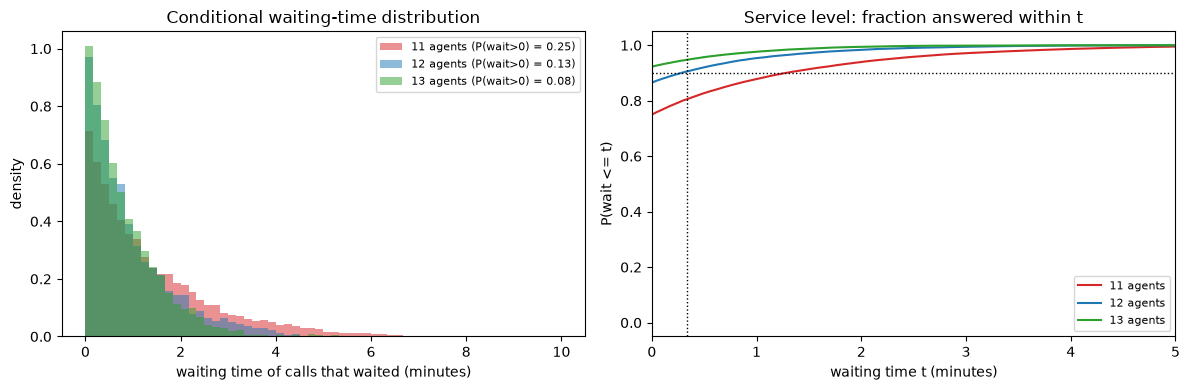

service level at 12 agents: 0.910 +/- 0.005 (standard error over 60 simulated days)
naive p(1-p)/n standard error would claim +/- 0.0012 -- too optimistic, because calls that queue together are correlated

with 10% more calls and the same 12 agents: service level 0.824, mean wait 0.28 min


In [19]:
rng = np.random.default_rng(2024)
RATE = 2.0            # calls per minute (Poisson arrivals)
MEAN_SERVICE = 4.0    # minutes (Exponential service)
HOURS = 8.0
WARMUP = 60.0         # minutes discarded so the system forgets its empty start
TARGET = 1 / 3        # 20 seconds

def simulate_day(c, rng, rate=RATE, mean_service=MEAN_SERVICE, hours=HOURS, warmup=WARMUP):
    T = hours * 60 + warmup
    gaps = rng.exponential(1 / rate, int(rate * T * 1.5) + 50)
    arrivals = np.cumsum(gaps)
    arrivals = arrivals[arrivals < T]
    service = rng.exponential(mean_service, arrivals.size)
    free_at = np.zeros(c)                     # when each agent becomes free
    waits = np.empty(arrivals.size)
    for i, (a, s) in enumerate(zip(arrivals, service)):
        j = np.argmin(free_at)                # the agent who is free earliest takes the call
        start = max(a, free_at[j])
        waits[i] = start - a
        free_at[j] = start + s
    return waits[arrivals >= warmup]

def erlang_c_service_level(lam, mu, c, t):
    # analytic M/M/c steady state: P(wait <= t)
    A = lam / mu
    if c <= A:
        return 0.0
    num = A**c / factorial(c) * c / (c - A)
    den = sum(A**k / factorial(k) for k in range(c)) + num
    p_wait = num / den
    return 1 - p_wait * exp(-(c * mu - lam) * t)

# sanity checks on the ingredients
test_gaps = rng.exponential(1 / RATE, 100_000)
print(f"arrival gaps: mean {test_gaps.mean():.3f} min (0.5), memoryless check P(gap > 1 | gap > 0.5) = {np.mean(test_gaps[test_gaps > 0.5] > 1.0):.3f} vs P(gap > 0.5) = {np.mean(test_gaps > 0.5):.3f}")
print(f"offered load = rate x mean service = {RATE * MEAN_SERVICE:.1f} agent-equivalents -> fewer than 9 agents cannot keep up\n")

results = {}
print(f"{'agents':>6s} {'occupancy':>9s} {'P(wait=0)':>9s} {'P(wait<=20s)':>13s} {'Erlang C':>9s} {'mean wait':>10s} {'90% wait':>9s} {'99% wait':>9s}")
for c in range(9, 16):
    w = np.concatenate([simulate_day(c, rng) for _ in range(60)])
    results[c] = w
    sl = np.mean(w <= TARGET)
    print(f"{c:6d} {RATE*MEAN_SERVICE/c:9.3f} {np.mean(w == 0):9.3f} {sl:13.3f} {erlang_c_service_level(RATE, 1/MEAN_SERVICE, c, TARGET):9.3f} "
          f"{w.mean():10.2f} {np.quantile(w, 0.9):9.2f} {np.quantile(w, 0.99):9.2f}")

staff = min(c for c, w in results.items() if np.mean(w <= TARGET) >= 0.9)
print(f"\nsmallest staffing with >= 90% of calls answered within 20 s: {staff} agents (occupancy {RATE*MEAN_SERVICE/staff:.0%})")

# waiting-time distribution for the chosen staffing and one agent fewer
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for c, col in [(staff - 1, "C3"), (staff, "C0"), (staff + 1, "C2")]:
    w = results[c]
    axes[0].hist(w[w > 0], bins=60, range=(0, 10), density=True, alpha=0.5, color=col, label=f"{c} agents (P(wait>0) = {np.mean(w > 0):.2f})")
    ws = np.sort(w)
    axes[1].plot(ws, np.arange(1, len(ws) + 1) / len(ws), color=col, label=f"{c} agents")
axes[0].set_xlabel("waiting time of calls that waited (minutes)"); axes[0].set_ylabel("density"); axes[0].set_title("Conditional waiting-time distribution"); axes[0].legend(fontsize=8)
axes[1].axhline(0.9, color="k", ls=":", lw=1); axes[1].axvline(TARGET, color="k", ls=":", lw=1)
axes[1].set_xlim(0, 5); axes[1].set_xlabel("waiting time t (minutes)"); axes[1].set_ylabel("P(wait <= t)"); axes[1].set_title("Service level: fraction answered within t"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# standard error of the service-level estimate for the chosen staffing: binomial-ish but calls within a day are correlated,
# so estimate it from day-to-day variation instead of p(1-p)/n
daily = np.array([np.mean(simulate_day(staff, rng) <= TARGET) for _ in range(60)])
print(f"service level at {staff} agents: {daily.mean():.3f} +/- {daily.std(ddof=1)/np.sqrt(len(daily)):.3f} (standard error over 60 simulated days)")
print(f"naive p(1-p)/n standard error would claim +/- {np.sqrt(daily.mean()*(1-daily.mean())/results[staff].size):.4f} -- too optimistic, because calls that queue together are correlated")

# sensitivity: 10% more traffic
w_busy = np.concatenate([simulate_day(staff, rng, rate=RATE * 1.1) for _ in range(60)])
print(f"\nwith 10% more calls and the same {staff} agents: service level {np.mean(w_busy <= TARGET):.3f}, mean wait {w_busy.mean():.2f} min")

## Score

In [20]:
summary()


Score: 65/65 checks passed  🎉
